0. Setup and reproducibility

In [66]:
# One install cell, no version pins. Pinning old versions (transformers==4.51.3, gptqmodel<3) is what
# forced a from-source build against the Colab torch and caused the compiler-error wall.
import importlib.metadata as ilm, subprocess, sys, os

def _have(dist):
    try: ilm.version(dist); return True
    except ilm.PackageNotFoundError: return False

PIP=[sys.executable,'-m','pip','install','-q']
if not _have('gptqmodel'):
    subprocess.check_call(PIP+['-U','setuptools','wheel','packaging','ninja'])
    subprocess.check_call(PIP+['-U','gptqmodel','--no-build-isolation'])
missing=[d for d in ('transformers','datasets','accelerate','scikit-learn','matplotlib','safetensors','pandas','tqdm') if not _have(d)]
if missing: subprocess.check_call(PIP+missing)

# Restart only if a package that is ALREADY imported in this kernel was changed on disk.
_CHECK={'numpy':'numpy','pandas':'pandas','pyarrow':'pyarrow','torch':'torch','PIL':'pillow','transformers':'transformers',
        'datasets':'datasets','tokenizers':'tokenizers','huggingface_hub':'huggingface_hub','accelerate':'accelerate',
        'safetensors':'safetensors'}
def _v(x): return str(x).split('+')[0]
stale=[m for m,d in _CHECK.items() if m in sys.modules and _have(d)
       and getattr(sys.modules[m],'__version__',None) is not None
       and _v(sys.modules[m].__version__)!=_v(ilm.version(d))]
if stale:
    print('Packages changed under the running kernel:',stale)
    print('>>> Restarting the runtime now. When it comes back, press Run all again. <<<')
    if 'google.colab' in sys.modules: os.kill(os.getpid(),9)
    else: raise SystemExit('Restart the kernel, then run all cells again.')
print('Environment ready:',{d:ilm.version(d) for d in ('torch','transformers','datasets','gptqmodel')})

Environment ready: {'torch': '2.15.0', 'transformers': '5.24.1', 'datasets': '5.2.0', 'gptqmodel': '7.12.2'}


In [67]:
import os, gc, json, time, random, math, shutil, pathlib, warnings, hashlib
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import torch.nn.functional as F
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSequenceClassification
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import accuracy_score
from IPython.display import display

SEED=2738
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
set_seed()
torch.backends.cudnn.deterministic=True; torch.backends.cudnn.benchmark=False
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
assert DEVICE=='cuda', 'GPU required: Runtime → Change runtime type → T4 GPU.'
print('Device:',torch.cuda.get_device_name(0)); print('Torch:',torch.__version__)
pd.set_option('display.max_colwidth', None)

Device: Tesla T4
Torch: 2.15.0+cu132


Experiment configuration:

Seed 2738 is provisional until verified against Assignment 1 Step 0. The base model must be instructor-approved; its revision is resolved to an immutable commit before loading.

**Teacher model:** the notebook looks for a teacher checkpoint in this order and never stops on a missing folder:
1. `TEACHER_PATH` below (or the `HW12_TEACHER_PATH` environment variable) — put the instructor-provided teacher folder here if you were given one;
2. `TEACHER_HUB_ID` — a Hugging Face model id, if you were given one;
3. otherwise it fine-tunes `bert-base-uncased` on AG News once and saves it to the work folder for reuse.

In [68]:
from huggingface_hub import HfApi

# ---- Model configuration ----
BASE_MODEL_ID = os.getenv('HW12_BASE_MODEL_ID', 'facebook/opt-125m')
BASE_REVISION = os.getenv('HW12_BASE_REVISION', 'main')
TEACHER_PATH  = os.getenv('HW12_TEACHER_PATH', '')      # folder with config.json + weights, if you have one
TEACHER_HUB_ID= os.getenv('HW12_TEACHER_HUB_ID', '')    # optional Hugging Face id of an AG News BERT teacher
TEACHER_BASE_ID='google-bert/bert-base-uncased'         # used only if no teacher checkpoint is found
STUDENT_ID    ='distilbert/distilbert-base-uncased'

# ---- GPTQ configuration ----
MAX_LENGTH_LM = 512
GPTQ_BITS = 4
GPTQ_GROUP_SIZE = 128
CALIBRATION_SAMPLES = 128
LM_EVAL_BLOCKS = 96
LM_BENCH_TOKENS = 128
LATENCY_REPEATS = 40
FORCE_REQUANTIZE = False     # True = ignore the cached quantized model

# ---- Knowledge distillation configuration ----
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 256
EPOCHS = 2
TEACHER_EPOCHS = 2
LR = 2e-5
WEIGHT_DECAY = 0.01
MAX_NEWS_LENGTH = 128
TRAIN_LIMIT = None           # e.g. 2000 for a 5-minute smoke test of the whole notebook; None for the real run
LOG_EVERY = 200
USE_AMP = True               # mixed precision for training/bulk inference (about 2x faster on a T4)
FORCE_RETRAIN = False        # True = ignore cached teacher/student runs

# ---- Storage: Google Drive if available (survives disconnects), otherwise local ----
USE_DRIVE = True
WORK = pathlib.Path('hw12_work')
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        WORK = pathlib.Path('/content/drive/MyDrive/DATA266/HW12')
    except Exception as e:
        print('Google Drive not used (', type(e).__name__, ') - saving locally instead.')
OUT = WORK/'outputs'                    # tables, plots, json (small files)
SCRATCH = pathlib.Path('hw12_scratch')  # large temporary models, local disk only
for d in (WORK, OUT, OUT/'runs', SCRATCH): d.mkdir(parents=True, exist_ok=True)

# Resolve the exact model revision (falls back to the given revision if the Hub lookup fails)
try:
    BASE_REVISION = HfApi().model_info(BASE_MODEL_ID, revision=BASE_REVISION).sha
except Exception as e:
    print('Could not resolve commit sha (', type(e).__name__, ') - using revision', BASE_REVISION)
print('Base model:', BASE_MODEL_ID, '| revision:', BASE_REVISION)
print('Work folder:', WORK.resolve())

save_config = dict(seed=SEED, base_model=BASE_MODEL_ID, revision=BASE_REVISION, batch_size=BATCH_SIZE, epochs=EPOCHS,
                   learning_rate=LR, weight_decay=WEIGHT_DECAY, gptq_bits=GPTQ_BITS, gptq_group_size=GPTQ_GROUP_SIZE,
                   calibration_samples=CALIBRATION_SAMPLES, train_limit=TRAIN_LIMIT, use_amp=USE_AMP,
                   max_news_length=MAX_NEWS_LENGTH)
(OUT/'configuration.json').write_text(json.dumps(save_config, indent=2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base model: facebook/opt-125m | revision: 27dcfa74d334bc871f3234de431e71c6eeba5dd6
Work folder: /content/drive/MyDrive/DATA266/HW12


340

Measurement utilities.

In [69]:
def clear_gpu():
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

def disk_mb(path):
    """Size of the saved weight files only (tokenizer/config files excluded so models are comparable)."""
    path=pathlib.Path(path)
    files=list(path.rglob('*.safetensors')) or list(path.rglob('*.bin'))
    return sum(f.stat().st_size for f in files)/1e6

def is_model_dir(path):
    path=pathlib.Path(path)
    return (path/'config.json').exists() and (any(path.glob('*.safetensors')) or any(path.glob('pytorch_model*.bin')))

@torch.inference_mode()
def benchmark(model, batch, repeats=LATENCY_REPEATS, warmup=8):
    """batch: dict of tensors. Returns p50/p95 latency (ms) and peak GPU memory (GB)."""
    model.eval(); batch={k:v.to('cuda') for k,v in batch.items()}
    clear_gpu()
    for _ in range(warmup): model(**batch)
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    times=[]
    for _ in range(repeats):
        torch.cuda.synchronize(); t=time.perf_counter()
        model(**batch); torch.cuda.synchronize()
        times.append((time.perf_counter()-t)*1000)
    return {'p50_ms':float(np.percentile(times,50)), 'p95_ms':float(np.percentile(times,95)),
            'peak_gb':torch.cuda.max_memory_allocated()/1e9}

def save_json(name,obj): (OUT/name).write_text(json.dumps(obj,indent=2,default=str))
def load_json(name,default=None):
    p=OUT/name
    return json.loads(p.read_text()) if p.exists() else default

Part 1 — GPTQ: same LLM, WikiText-2 and hardware

In [70]:
wiki=load_dataset('Salesforce/wikitext','wikitext-2-raw-v1')
lm_tok=AutoTokenizer.from_pretrained(BASE_MODEL_ID,revision=BASE_REVISION)
if lm_tok.pad_token is None: lm_tok.pad_token=lm_tok.eos_token

cal_texts=[s.strip() for s in wiki['train']['text'] if len(s.strip())>100][:CALIBRATION_SAMPLES]
assert len(cal_texts)==CALIBRATION_SAMPLES

# Fixed contiguous token blocks: identical token IDs for the base and the quantized model.
eval_text='\n\n'.join(x for x in wiki['test']['text'] if x.strip())
all_ids=lm_tok(eval_text,return_tensors='pt',add_special_tokens=False,verbose=False)['input_ids'][0]
blocks=[all_ids[i:i+MAX_LENGTH_LM] for i in range(0,len(all_ids)-MAX_LENGTH_LM+1,MAX_LENGTH_LM)][:LM_EVAL_BLOCKS]
assert blocks, 'No LM evaluation blocks available'
print('Calibration texts:',len(cal_texts),'| evaluation blocks:',len(blocks))

@torch.inference_mode()
def lm_perplexity(model):
    model.eval(); nll=0.; ntok=0
    for x in tqdm(blocks,desc='WikiText-2 perplexity'):
        inp=x.unsqueeze(0).to('cuda')
        out=model(input_ids=inp,labels=inp)
        count=inp.numel()-1          # causal LM shifts internally: predicts positions 1..L-1
        nll+=float(out.loss)*count; ntok+=count
    return math.exp(nll/ntok)

lm_bench_ids=blocks[0][:LM_BENCH_TOKENS].unsqueeze(0)
lm_bench={'input_ids':lm_bench_ids,'attention_mask':torch.ones_like(lm_bench_ids)}
lm_results={}

Calibration texts: 128 | evaluation blocks: 96


In [71]:
# Unquantized baseline (fp16 is the documented baseline precision). Fast, so it is always re-measured
# in the same session as the quantized model.
clear_gpu()
base_lm=AutoModelForCausalLM.from_pretrained(BASE_MODEL_ID,revision=BASE_REVISION).half().to('cuda').eval()
base_path=SCRATCH/'base_llm'
if base_path.exists(): shutil.rmtree(base_path)
base_lm.save_pretrained(base_path,safe_serialization=True)
base_ppl=lm_perplexity(base_lm)
lm_results['Base LLM']={'perplexity':base_ppl,**benchmark(base_lm,lm_bench),'disk_mb':disk_mb(base_path)}
save_json('lm_results.json',lm_results)
print(lm_results['Base LLM'])
del base_lm; clear_gpu()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

WikiText-2 perplexity:   0%|          | 0/96 [00:00<?, ?it/s]

{'perplexity': 43.986902373491574, 'p50_ms': 38.84649400015405, 'p95_ms': 64.85122634994696, 'peak_gb': 0.276785664, 'disk_mb': 250.500968}


### GPTQ quantization
The quantized model is saved to the work folder; later runs load it instead of quantizing again (set `FORCE_REQUANTIZE=True` to redo it).

In [72]:
import gptqmodel
from gptqmodel import GPTQModel, QuantizeConfig
print('GPTQModel:',gptqmodel.__version__)

# Colab has 2 CPU cores: keep GPTQModel's worker pool at 2. Skipped silently if this version has no such knob.
try:
    from gptqmodel import resize_device_thread_pool as _resize
    def _fixed_resize(*args,**kwargs):
        kwargs['cpu_workers']=min(2,os.cpu_count() or 2); return _resize(*args,**kwargs)
    gptqmodel.resize_device_thread_pool=_fixed_resize
    _fixed_resize()
except Exception as e:
    print('Thread-pool resize skipped:',type(e).__name__,e)

quant_path=WORK/'gptq_llm'
quant_tag={'model':BASE_MODEL_ID,'revision':BASE_REVISION,'bits':GPTQ_BITS,'group_size':GPTQ_GROUP_SIZE,
           'calibration_samples':CALIBRATION_SAMPLES}
tag_file=quant_path/'hw12_quant_tag.json'
cached=(not FORCE_REQUANTIZE and is_model_dir(quant_path) and tag_file.exists()
        and json.loads(tag_file.read_text())==quant_tag)

if cached:
    print('Using cached quantized model:',quant_path)
else:
    from huggingface_hub import snapshot_download
    clear_gpu()
    if quant_path.exists(): shutil.rmtree(quant_path)
    local_model_path=snapshot_download(repo_id=BASE_MODEL_ID,revision=BASE_REVISION)
    quant_config=QuantizeConfig(bits=GPTQ_BITS,group_size=GPTQ_GROUP_SIZE)
    quant_wrapper=GPTQModel.load(local_model_path,quantize_config=quant_config)
    try:        # API of recent GPTQModel releases (the one that ran in this Colab image)
        from gptqmodel.models.base import CalibrationConfig
        quant_wrapper.quantize(calibration=CalibrationConfig(dataset=cal_texts),tokenizer=lm_tok)
    except (ImportError,TypeError):   # older releases: calibration data is passed directly
        quant_wrapper.quantize(cal_texts)
    quant_path.mkdir(parents=True,exist_ok=True)
    quant_wrapper.save(str(quant_path))
    tag_file.write_text(json.dumps(quant_tag))
    del quant_wrapper; clear_gpu()
    print('Quantized model saved to',quant_path)

GPTQModel: 7.12.2


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_f7bjjgqg`
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  LazyTurtle: no safetensors found under `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6`; converting `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6/pytorch_model.bin` into cached safetensors at `/tmp/gptqmodel_f7bjjgqg/lazyturtle-9010-d5053242365f1c5b`.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

INFO  Loader: using checkpoint-backed lazy turtle source for `/root/.cache/huggingface/hub/models--facebook--opt-125m/snapshots/27dcfa74d334bc871f3234de431e71c6eeba5dd6`
INFO  Model: Loaded `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "output_attentions": false,   "output_hidden_states": false,   "pad_token_id": 1,   "use_cache": true } 
INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "pad_token_id": 1 } 
INFO  Kernel: loaded -> `[]`                                                    
INFO  Budget: weights 0 B (measured)                                            
INFO  Budget: KV cache 36 KiB/token (12 growing layer(s), gqa, float16) | 8k ctx 288 MiB | 32k ctx 1.1 GiB (estimated)
INFO  Packing Kernel: selected: `TorchLinear`                                   
INFO  Packing Kernel: selected: `Tor

In [73]:
# Reload the quantized model from disk and measure it exactly like the baseline.
clear_gpu()
quant_wrapper=GPTQModel.load(str(quant_path),device='cuda')
quant_lm=quant_wrapper.model.eval()
assert all(p.device.type=='cuda' for p in quant_lm.parameters()), 'CPU offload invalidates comparison'
quant_ppl=lm_perplexity(quant_lm)
lm_results['GPTQ-quantized LLM']={'perplexity':quant_ppl,**benchmark(quant_lm,lm_bench),'disk_mb':disk_mb(quant_path)}
save_json('lm_results.json',lm_results)
print(lm_results['GPTQ-quantized LLM'])
del quant_lm,quant_wrapper; clear_gpu()

from_quantized: adapter: None
INFO  Loader: Auto dtype (native float16): `torch.float16`                      
INFO  QuantizeConfig: offload_to_disk_path auto set to temporary dir `/tmp/gptqmodel_6uz48qem`
INFO  Estimated Quantization BPW (bits per weight): 4.2875 bpw, based on [bits: 4, group_size: 128]
INFO  The layer model.decoder.embed_tokens is not quantized.                    
INFO  The layer model.decoder.embed_positions is not quantized.                 
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`                
INFO  Kernel: Auto-selection: adding candidate `TritonV2Linear`                 
INFO  Kernel: Auto-selection: adding candidate `TorchLinear`                    
INFO  Kernel: candidates -> `[ExllamaV2Linear, TritonV2Linear, TorchLinear]`    
INFO  Kernel: per-module selections -> `[ExllamaV2Linear=72]`                   
INFO  Kernel: selected -> `ExllamaV2Linear`.                                    
INFO  Loader: device = (device(type='cuda', in

INFO  Format: Converting `format` from `FORMAT.GPTQ` to internal `FORMAT.GPTQ_V2`.
INFO  Kernel: Auto-selection: adding candidate `ExllamaV2Linear`                
INFO  Kernel: selected -> `ExllamaV2Linear`.                                    
INFO  gc.collect() reclaimed 0 objects in 2.257s                                
INFO  Model: Loaded `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "output_attentions": false,   "output_hidden_states": false,   "pad_token_id": 1,   "use_cache": true } 
INFO  Model: Auto-fixed `generation_config` mismatch between model and `generation_config.json`.
INFO  Model: Updated `generation_config`: GenerationConfig {   "bos_token_id": 2,   "eos_token_id": 2,   "pad_token_id": 1 } 
INFO  Kernel: loaded -> `[ExllamaV2Linear]`                                     
INFO  Budget: weights 119.3 MiB (measured), device 0 free 14.2 GiB of 14.6 GiB (measured), host 576 B (measured)
INFO  Budget: KV cache 36 KiB/token (12 growing 

WikiText-2 perplexity:   0%|          | 0/96 [00:00<?, ?it/s]

{'perplexity': 46.62960719324526, 'p50_ms': 44.728782499987574, 'p95_ms': 72.83727955050381, 'peak_gb': 0.1517184, 'disk_mb': 125.11368}


In [74]:
lm_table=pd.DataFrame(lm_results).T.rename(columns={'perplexity':'WikiText-2 perplexity',
 'p50_ms':'p50 latency (ms)','p95_ms':'p95 latency (ms)','peak_gb':'Peak GPU memory (GB)','disk_mb':'Size on disk (MB)'})
display(lm_table.round(3)); lm_table.to_csv(OUT/'table_hw11_1.csv')
b,q=lm_results['Base LLM'],lm_results['GPTQ-quantized LLM']
print('Perplexity change (%):',round(100*(q['perplexity']/b['perplexity']-1),2))
print('p50 speedup:',round(b['p50_ms']/q['p50_ms'],2))
print('Disk compression ratio:',round(b['disk_mb']/q['disk_mb'],2))

,WikiText-2 perplexity,p50 latency (ms),p95 latency (ms),Peak GPU memory (GB),Size on disk (MB)
Base LLM,43.987,38.846,64.851,0.277,250.501
GPTQ-quantized LLM,46.630,44.729,72.837,0.152,125.114


Perplexity change (%): 6.01
p50 speedup: 0.87
Disk compression ratio: 2.0


## Part 2 — BERT teacher → DistilBERT student on AG News

In [75]:
news=load_dataset('fancyzhx/ag_news')
label_names=news['train'].features['label'].names
NUM_LABELS=len(label_names)
train_raw=news['train'] if TRAIN_LIMIT is None else news['train'].select(range(TRAIN_LIMIT))
test_raw=news['test']
test_labels=np.asarray(test_raw['label'])
print('Labels:',label_names,'| train:',len(train_raw),'| test:',len(test_raw))

# ---- Find a teacher checkpoint; never stop on a missing folder ----
teacher_candidates=[p for p in (TEACHER_PATH,'teacher_model',str(WORK/'teacher_model')) if p]
teacher_dir=next((pathlib.Path(p) for p in teacher_candidates if is_model_dir(p)),None)
if FORCE_RETRAIN and teacher_dir is not None and teacher_dir==WORK/'teacher_model': teacher_dir=None
if teacher_dir is not None:
    TEACHER_SOURCE=str(teacher_dir); TEACHER_MODE='checkpoint'
elif TEACHER_HUB_ID:
    TEACHER_SOURCE=TEACHER_HUB_ID; TEACHER_MODE='hub'
else:
    TEACHER_SOURCE=TEACHER_BASE_ID; TEACHER_MODE='finetune'; teacher_dir=WORK/'teacher_model'
print('Teacher mode:',TEACHER_MODE,'| source:',TEACHER_SOURCE)

try: teacher_tok=AutoTokenizer.from_pretrained(TEACHER_SOURCE)
except Exception: teacher_tok=AutoTokenizer.from_pretrained(TEACHER_BASE_ID)   # checkpoint folder without tokenizer files
student_tok=AutoTokenizer.from_pretrained(STUDENT_ID)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

... (6 outputs left out)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [76]:
# Tokenize separately for teacher and student; tokenizers are not assumed identical.
def tokenize_split(split,tok):
    return split.map(lambda x:tok(x['text'],truncation=True,max_length=MAX_NEWS_LENGTH),batched=True,
                     remove_columns=['text'])
teach_train=tokenize_split(train_raw,teacher_tok); teach_test=tokenize_split(test_raw,teacher_tok)
stud_train=tokenize_split(train_raw,student_tok);  stud_test=tokenize_split(test_raw,student_tok)

class EncodedDataset(Dataset):
    def __init__(self,data,logits=None): self.data=data; self.logits=logits
    def __len__(self): return len(self.data)
    def __getitem__(self,i):
        row=self.data[int(i)]
        d={'input_ids':row['input_ids'],'attention_mask':row['attention_mask'],'labels':int(row['label'])}
        if self.logits is not None: d['teacher_logits']=self.logits[int(i)]
        return d

def collator_for(tok):
    def collate(items):
        out=tok.pad([{'input_ids':x['input_ids'],'attention_mask':x['attention_mask']} for x in items],return_tensors='pt')
        out={'input_ids':out['input_ids'],'attention_mask':out['attention_mask'],
             'labels':torch.tensor([x['labels'] for x in items],dtype=torch.long)}
        if 'teacher_logits' in items[0]:
            out['teacher_logits']=torch.as_tensor(np.stack([x['teacher_logits'] for x in items]),dtype=torch.float32)
        return out
    return collate

def loader(data,tok,bs=BATCH_SIZE,shuffle=False,logits=None):
    return DataLoader(EncodedDataset(data,logits),batch_size=bs,shuffle=shuffle,collate_fn=collator_for(tok),
                      generator=torch.Generator().manual_seed(SEED))

def bench_batch(tok):
    """One test example padded to MAX_NEWS_LENGTH: same shape for teacher and student."""
    enc=tok(test_raw[0]['text'],truncation=True,max_length=MAX_NEWS_LENGTH,padding='max_length',return_tensors='pt')
    return {'input_ids':enc['input_ids'],'attention_mask':enc['attention_mask']}

@torch.inference_mode()
def predict_logits(model,dl,description='Predict'):
    model.eval(); outputs=[]
    for batch in tqdm(dl,desc=description):
        feats={k:batch[k].to('cuda') for k in ('input_ids','attention_mask')}
        with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
            logits=model(**feats).logits
        outputs.append(logits.float().cpu().numpy())
    return np.concatenate(outputs)

def fit(model,dl,epochs,loss_fn,tag):
    """Shared training loop (AdamW, linear warmup/decay, grad clipping, optional AMP). Returns loss logs."""
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    steps=len(dl)*epochs; warm=int(.1*steps)
    scheduler=torch.optim.lr_scheduler.LambdaLR(optimizer,
        lambda s: s/max(1,warm) if s<warm else max(0.0,(steps-s)/max(1,steps-warm)))
    scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
    logs=[]
    for epoch in range(epochs):
        model.train(); sums=np.zeros(3); n_batches=0
        for step,batch in enumerate(tqdm(dl,desc=f'{tag} epoch {epoch+1}/{epochs}'),1):
            batch={k:v.to('cuda') for k,v in batch.items()}
            labels=batch.pop('labels'); target_logits=batch.pop('teacher_logits',None)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16,enabled=USE_AMP):
                pred=model(**batch).logits
            loss,ce,kd=loss_fn(pred.float(),target_logits,labels)      # loss computed in float32
            scaler.scale(loss).backward(); scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            sums+=np.array([loss.item(),float(ce),float(kd)]); n_batches+=1
            if step%LOG_EVERY==0 or step==len(dl):
                scores=sums/n_batches
                logs.append({'tag':tag,'epoch':epoch+1,'step':epoch*len(dl)+step,
                             'loss':float(scores[0]),'ce':float(scores[1]),'kd':float(scores[2])})
                sums=np.zeros(3); n_batches=0
    return logs

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

In [77]:
# Teacher: load (or fine-tune once), then cache its logits and measurements so this cell is skipped on re-runs.
teacher_sig={'source':TEACHER_SOURCE,'mode':TEACHER_MODE,'n_train':len(train_raw),'max_len':MAX_NEWS_LENGTH,
             'teacher_epochs':TEACHER_EPOCHS if TEACHER_MODE=='finetune' else None}
t_cache=load_json('teacher_cache.json')
logit_files=[OUT/'teacher_train_logits.npy',OUT/'teacher_test_logits.npy']
if (not FORCE_RETRAIN and t_cache and t_cache.get('sig')==teacher_sig and all(f.exists() for f in logit_files)
        and (TEACHER_MODE=='hub' or is_model_dir(teacher_dir))):
    teacher_train_logits=np.load(logit_files[0]); teacher_test_logits=np.load(logit_files[1])
    teacher_stats=t_cache['stats']
    print('Using cached teacher logits and measurements.')
else:
    clear_gpu(); set_seed()
    if TEACHER_MODE=='finetune':
        print('No teacher checkpoint found - fine-tuning',TEACHER_BASE_ID,'on AG News (done once, then reused).')
        teacher=AutoModelForSequenceClassification.from_pretrained(TEACHER_BASE_ID,num_labels=NUM_LABELS,
                    id2label=dict(enumerate(label_names)),label2id={n:i for i,n in enumerate(label_names)}).to('cuda')
        ce_only=lambda pred,_,labels:(F.cross_entropy(pred,labels),)*2+(0.0,)
        teacher_logs=fit(teacher,loader(teach_train,teacher_tok,shuffle=True),TEACHER_EPOCHS,ce_only,'teacher')
        pd.DataFrame(teacher_logs).to_csv(OUT/'teacher_training_logs.csv',index=False)
        teacher.save_pretrained(teacher_dir,safe_serialization=True); teacher_tok.save_pretrained(teacher_dir)
    else:
        teacher=AutoModelForSequenceClassification.from_pretrained(TEACHER_SOURCE).to('cuda')
    assert teacher.config.num_labels==NUM_LABELS,'Teacher must have four AG News output labels.'
    print('Teacher label mapping:',teacher.config.id2label)
    # Logits for EVERY training example in fixed dataset order.
    teacher_train_logits=predict_logits(teacher,loader(teach_train,teacher_tok,bs=EVAL_BATCH_SIZE),'Teacher training logits')
    teacher_test_logits=predict_logits(teacher,loader(teach_test,teacher_tok,bs=EVAL_BATCH_SIZE),'Teacher test logits')
    assert len(teacher_train_logits)==len(train_raw)
    np.save(logit_files[0],teacher_train_logits); np.save(logit_files[1],teacher_test_logits)
    if TEACHER_MODE=='hub':
        teacher_dir=SCRATCH/'teacher_copy'; teacher.save_pretrained(teacher_dir,safe_serialization=True)
    teacher_stats=benchmark(teacher,bench_batch(teacher_tok))
    teacher_stats['accuracy']=float(accuracy_score(test_labels,teacher_test_logits.argmax(1)))
    teacher_stats['disk_mb']=disk_mb(teacher_dir)
    save_json('teacher_cache.json',{'sig':teacher_sig,'stats':teacher_stats})
    del teacher; clear_gpu()

teacher_predictions=teacher_test_logits.argmax(1)
teacher_accuracy=teacher_stats['accuracy']
if teacher_accuracy<.90:
    warnings.warn('Teacher accuracy is below 90%: inspect the checkpoint and its label mapping.')
print('Teacher:',teacher_stats)

No teacher checkpoint found - fine-tuning google-bert/bert-base-uncased on AG News (done once, then reused).


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


teacher epoch 1/2:   0%|          | 0/3750 [00:00<?, ?it/s]

... (3 outputs left out)

Teacher label mapping: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}


Teacher training logits:   0%|          | 0/469 [00:00<?, ?it/s]

Teacher test logits:   0%|          | 0/30 [00:00<?, ?it/s]

Teacher: {'p50_ms': 9.638384499794483, 'p95_ms': 10.186162249738116, 'peak_gb': 0.880236032, 'accuracy': 0.9468421052631579, 'disk_mb': 437.964776}


Distillation objective

In [78]:
def distill_loss(student_logits,teacher_logits,labels,temperature,alpha):
    ce=F.cross_entropy(student_logits,labels)
    kd=F.kl_div(F.log_softmax(student_logits/temperature,dim=-1),
                F.softmax(teacher_logits/temperature,dim=-1),reduction='batchmean')
    return alpha*ce+(1-alpha)*temperature**2*kd,ce.detach(),kd.detach()

RUNS_LOCAL=SCRATCH/'student_runs'
run_sig={'seed':SEED,'epochs':EPOCHS,'lr':LR,'wd':WEIGHT_DECAY,'bs':BATCH_SIZE,'n_train':len(train_raw),
         'max_len':MAX_NEWS_LENGTH,'amp':USE_AMP,'student':STUDENT_ID,
         'teacher_logits':hashlib.md5(np.ascontiguousarray(teacher_train_logits).tobytes()).hexdigest()}

def run_student(temperature,alpha,need_model=False):
    """Train one student (or load its cached result). Returns dict(tag, T, alpha, acc, preds, logs, model_dir)."""
    tag=f'T{temperature}_a{alpha}'
    meta_file=OUT/'runs'/f'{tag}.json'; pred_file=OUT/'runs'/f'{tag}_test_logits.npy'; model_dir=RUNS_LOCAL/tag
    if not FORCE_RETRAIN and meta_file.exists() and pred_file.exists():
        meta=json.loads(meta_file.read_text())
        if meta.get('sig')==run_sig and (not need_model or is_model_dir(model_dir)):
            print(f'[{tag}] cached: test accuracy {meta["acc"]:.4f}')
            return {'tag':tag,'T':temperature,'alpha':alpha,'acc':meta['acc'],'preds':np.load(pred_file),
                    'logs':meta['logs'],'model_dir':model_dir}
    clear_gpu(); set_seed()
    model=AutoModelForSequenceClassification.from_pretrained(STUDENT_ID,num_labels=NUM_LABELS,
              id2label=dict(enumerate(label_names)),label2id={n:i for i,n in enumerate(label_names)}).to('cuda')
    dl=loader(stud_train,student_tok,shuffle=True,logits=teacher_train_logits)
    logs=fit(model,dl,EPOCHS,lambda p,t,y:distill_loss(p,t,y,temperature,alpha),tag)
    preds=predict_logits(model,loader(stud_test,student_tok,bs=EVAL_BATCH_SIZE),f'{tag} test')
    acc=float(accuracy_score(test_labels,preds.argmax(1)))
    if model_dir.exists(): shutil.rmtree(model_dir)
    model.save_pretrained(model_dir,safe_serialization=True)
    np.save(pred_file,preds); meta_file.write_text(json.dumps({'sig':run_sig,'acc':acc,'logs':logs}))
    print(f'[{tag}] test accuracy {acc:.4f} | final loss {logs[-1]["loss"]:.4f}')
    del model; clear_gpu()
    return {'tag':tag,'T':temperature,'alpha':alpha,'acc':acc,'preds':preds,'logs':logs,'model_dir':model_dir}

all_runs={}

## Part 3A — Temperature sweep: T = 1, 2, 5, 10 (α = 0.5)

In [79]:
for T in (1,2,5,10):
    r=run_student(T,0.5); all_runs[r['tag']]=r
temp_df=pd.DataFrame([{'T':T,'alpha':0.5,'test_accuracy':all_runs[f'T{T}_a0.5']['acc']} for T in (1,2,5,10)])
best_T=int(temp_df.sort_values(['test_accuracy','T'],ascending=[False,True]).iloc[0]['T'])
print('Best T:',best_T); display(temp_df)
temp_df.to_csv(OUT/'temperature_sweep.csv',index=False)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T1_a0.5 epoch 1/2:   0%|          | 0/3750 [00:00<?, ?it/s]

T1_a0.5 epoch 2/2:   0%|          | 0/3750 [00:00<?, ?it/s]

... (21 outputs left out)

T10_a0.5 test:   0%|          | 0/30 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[T10_a0.5] test accuracy 0.9471 | final loss 0.1078
Best T: 10


,T,alpha,test_accuracy
0,1,0.5,0.945000
1,2,0.5,0.944474
2,5,0.5,0.946447
3,10,0.5,0.947105


Part 3B — Alpha sweep: α = 0.25, 0.5, 0.75 at best T

In [80]:
for alpha in (0.25,0.5,0.75):
    r=run_student(best_T,alpha); all_runs[r['tag']]=r
alpha_df=pd.DataFrame([{'T':best_T,'alpha':a,'test_accuracy':all_runs[f'T{best_T}_a{a}']['acc']} for a in (0.25,0.5,0.75)])
display(alpha_df); alpha_df.to_csv(OUT/'alpha_sweep.csv',index=False)
best_alpha=float(alpha_df.sort_values(['test_accuracy','alpha'],ascending=[False,True]).iloc[0]['alpha'])

# Make sure the best model's weights exist (retrains only that one run if the local copy was lost in a disconnect).
best_run=run_student(best_T,best_alpha,need_model=True); all_runs[best_run['tag']]=best_run
best_accuracy=best_run['acc']; best_preds=best_run['preds'].argmax(1)
best_path=WORK/'best_distilled_student'
if best_path.exists(): shutil.rmtree(best_path)
shutil.copytree(best_run['model_dir'],best_path); student_tok.save_pretrained(best_path)

logs_df=pd.DataFrame([row for r in all_runs.values() for row in r['logs']])
logs_df.to_csv(OUT/'training_logs.csv',index=False)
print('Best: T =',best_T,'| alpha =',best_alpha,'| test accuracy =',round(best_accuracy,4))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


T10_a0.25 epoch 1/2:   0%|          | 0/3750 [00:00<?, ?it/s]

T10_a0.25 epoch 2/2:   0%|          | 0/3750 [00:00<?, ?it/s]

T10_a0.25 test:   0%|          | 0/30 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[T10_a0.75] test accuracy 0.9461 | final loss 0.1245


,T,alpha,test_accuracy
0,10,0.25,0.946447
1,10,0.50,0.947105
2,10,0.75,0.946053


[T10_a0.5] cached: test accuracy 0.9471
Best: T = 10 | alpha = 0.5 | test accuracy = 0.9471


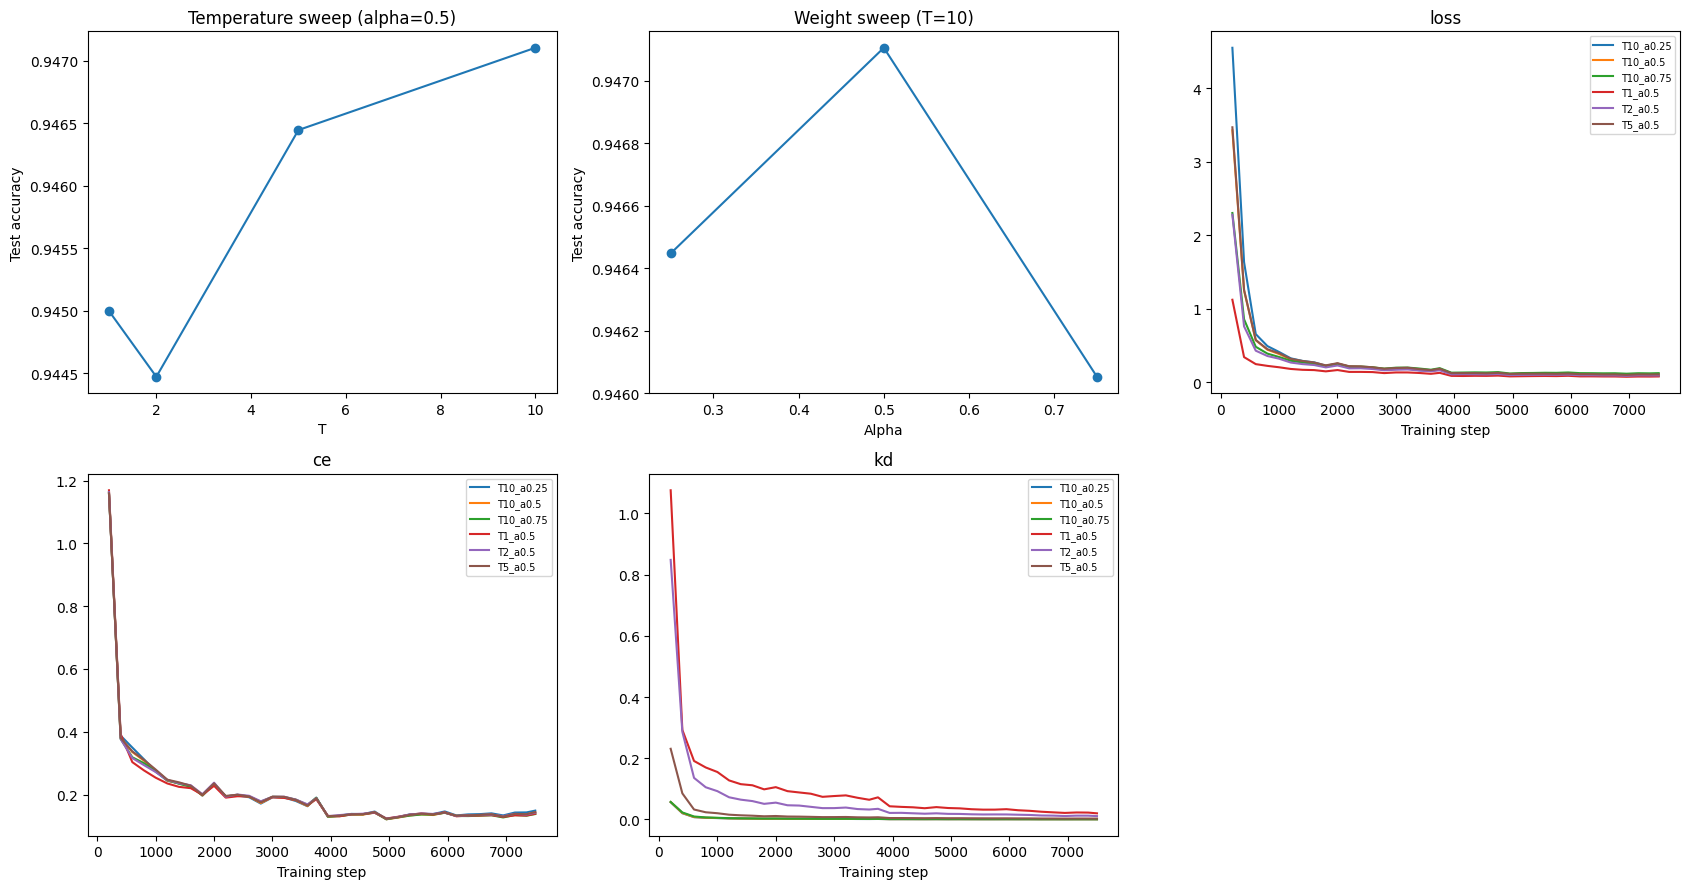

,tag,epoch,step,loss,ce,kd
0,T1_a0.5,1,200,1.122342,1.168929,1.075756
1,T1_a0.5,1,400,0.342585,0.392398,0.292771
2,T1_a0.5,1,600,0.247181,0.303125,0.191237
3,T1_a0.5,1,800,0.223352,0.276699,0.170005
4,T1_a0.5,1,1000,0.204362,0.253567,0.155156
5,T1_a0.5,1,1200,0.181408,0.235142,0.127674
6,T1_a0.5,1,1400,0.169898,0.224378,0.115418
7,T1_a0.5,1,1600,0.165994,0.220213,0.111774
8,T1_a0.5,1,1800,0.148824,0.199170,0.098478
9,T1_a0.5,1,2000,0.166661,0.227689,0.105633


In [81]:
fig,axs=plt.subplots(2,3,figsize=(17,9)); axs=axs.ravel()
axs[0].plot(temp_df['T'],temp_df['test_accuracy'],marker='o'); axs[0].set(title='Temperature sweep (alpha=0.5)',xlabel='T',ylabel='Test accuracy')
axs[1].plot(alpha_df['alpha'],alpha_df['test_accuracy'],marker='o'); axs[1].set(title=f'Weight sweep (T={best_T})',xlabel='Alpha',ylabel='Test accuracy')
for ax,metric in zip(axs[2:5],['loss','ce','kd']):
    for tag,group in logs_df.groupby('tag'):
        ax.plot(group['step'],group[metric],label=tag)
    ax.set(title=metric,xlabel='Training step'); ax.legend(fontsize=7)
axs[5].axis('off')
plt.tight_layout(); plt.savefig(OUT/'sweeps_and_loss.png',dpi=150); plt.show()
display(logs_df.head(10))

Part 3C — Per-class accuracy and five teacher-correct/student-wrong examples

In [82]:
def per_class_accuracy(y_true,y_pred):
    return [float((y_pred[y_true==k]==k).mean()) for k in range(NUM_LABELS)]
tpc=per_class_accuracy(test_labels,teacher_predictions)
spc=per_class_accuracy(test_labels,best_preds)
class_df=pd.DataFrame({'class':label_names,'teacher_accuracy':tpc,'student_accuracy':spc,
                       'student_minus_teacher':np.asarray(spc)-np.asarray(tpc)})
display(class_df); class_df.to_csv(OUT/'per_class_accuracy.csv',index=False)
worst_class=int(np.argmin(np.asarray(spc)-np.asarray(tpc)))
print('Largest degradation:',label_names[worst_class])
fail_idx=np.where((test_labels==worst_class)&(teacher_predictions==test_labels)&(best_preds!=test_labels))[0]
if len(fail_idx)<5:
    print('Fewer than five failures in worst class; supplementing from other classes.')
    other=np.where((teacher_predictions==test_labels)&(best_preds!=test_labels)&(test_labels!=worst_class))[0]
    fail_idx=np.concatenate([fail_idx,other])
examples=[]
for i in fail_idx[:5]:
    examples.append({'index':int(i),'true_class':label_names[int(test_labels[i])],
      'teacher_prediction':label_names[int(teacher_predictions[i])],
      'student_prediction':label_names[int(best_preds[i])],'text':test_raw[int(i)]['text']})
example_df=pd.DataFrame(examples); display(example_df)
example_df.to_csv(OUT/'five_failure_examples.csv',index=False)
for e in examples:
    print(e['index'], e['true_class'], '→', e['student_prediction'], '\n', e['text'], '\n')
if len(examples)<5: print('Only',len(examples),'qualifying examples exist.')

,class,teacher_accuracy,student_accuracy,student_minus_teacher
0,World,0.956316,0.954211,-0.002105
1,Sports,0.987895,0.988947,0.001053
2,Business,0.913158,0.911053,-0.002105
3,Sci/Tech,0.930000,0.934211,0.004211


Largest degradation: World


,index,true_class,teacher_prediction,student_prediction,text
0,141,World,World,Sci/Tech,"Bush Promotes His Plan for Missile Defense System President Bush, in Pennsylvania, said that opponents of a missile defense system were putting the nation's security at risk."
1,1599,World,World,Sports,"Two gored to death in Spanish bull-run Two Spanish men were gored to death by fighting bulls yesterday during the bull-run at the local fiestas in Ampuero, a town 30 miles east of the northern port city of Santander."
2,1946,World,World,Business,"\$78,000 for a Cane That Helped a Legend Walk the Line Many of Johnny Cash's possessions were sold at Sotheby's, collecting \$3,984,260 for the Cash family, more than double the pre-auction estimate."
3,2247,World,World,Business,"Asia to outperform this year, lower growth seen in 2005: ADB (AFP) AFP - Developing Asia is set to outperform this year with higher-than-expected growth of 7.0 percent despite high oil prices but it will slow in 2005 in tandem with the developed world, the Asian Development Bank (ADB) said."
4,2392,World,World,Business,Feed-Tube Law Is Struck Down in Florida Case The court said that Gov. Jeb Bush violated separation of powers when he signed a law to keep Theresa Schiavo alive.


141 World → Sci/Tech 
 Bush Promotes His Plan for Missile Defense System President Bush, in Pennsylvania, said that opponents of a missile defense system were putting the nation's security at risk. 

1599 World → Sports 
 Two gored to death in Spanish bull-run Two Spanish men were gored to death by fighting bulls yesterday during the bull-run at the local fiestas in Ampuero, a town 30 miles east of the northern port city of Santander. 

1946 World → Business 
 \$78,000 for a Cane That Helped a Legend Walk the Line Many of Johnny Cash's possessions were sold at Sotheby's, collecting \$3,984,260 for the Cash family, more than double the pre-auction estimate. 

2247 World → Business 
 Asia to outperform this year, lower growth seen in 2005: ADB (AFP) AFP - Developing Asia is set to outperform this year with higher-than-expected growth of 7.0 percent despite high oil prices but it will slow in 2005 in tandem with the developed world, the Asian Development Bank (ADB) said. 

2392 World → Bu

Part 3D — Teacher vs best student: accuracy, latency, memory, disk size

In [83]:
clear_gpu()
best_student=AutoModelForSequenceClassification.from_pretrained(str(best_path)).to('cuda')
student_stats=benchmark(best_student,bench_batch(student_tok))
student_stats['accuracy']=best_accuracy; student_stats['disk_mb']=disk_mb(best_path)
del best_student; clear_gpu()
classification_results={'Teacher (BERT-base)':teacher_stats,'Best distilled student':student_stats}
save_json('classification_results.json',classification_results)
classification_table=pd.DataFrame(classification_results).T.rename(columns={
 'accuracy':'Accuracy','p50_ms':'p50 latency (ms)','p95_ms':'p95 latency (ms)',
 'peak_gb':'Peak GPU memory (GB)','disk_mb':'Size on disk (MB)'})
classification_table=classification_table[['Accuracy','p50 latency (ms)','p95 latency (ms)','Peak GPU memory (GB)','Size on disk (MB)']]
display(classification_table.round(3)); classification_table.to_csv(OUT/'table_hw11_2.csv')
print('Student/teacher accuracy difference:',round(best_accuracy-teacher_accuracy,4))
print('Teacher/student p50 latency ratio:',round(teacher_stats['p50_ms']/student_stats['p50_ms'],3))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,Accuracy,p50 latency (ms),p95 latency (ms),Peak GPU memory (GB),Size on disk (MB)
Teacher (BERT-base),0.947,9.638,10.186,0.880,437.965
Best distilled student,0.947,5.040,8.131,0.272,267.839


Student/teacher accuracy difference: 0.0003
Teacher/student p50 latency ratio: 1.912


Conclusion:

GPTQ halved the LLM's size on disk (250.5 to 125.1 MB) and cut peak GPU memory by 45%, at the cost of a 6.0% rise in perplexity (43.99 to 46.63). It did not speed up inference: p50 latency rose from 38.9 to 44.7 ms, so for a model this small on a T4, 4-bit quantization is a memory and storage optimization, not a latency one. Knowledge distillation produced a DistilBERT student that matched its BERT teacher's accuracy (94.71% vs 94.68%) while running 1.91× faster, using 69% less peak GPU memory and 1.64× less disk. The best setting was T = 10 and α = 0.5, but all six student runs fell between 94.45% and 94.71%, so the effect of temperature and alpha is within noise. For a latency-bound deployment I would choose distillation; for a storage-bound deployment of a fixed model, GPTQ. The two accuracy figures are not directly comparable, because one task is language modeling and the other is classification.